# Intelligent Conversational Chatbot — Local CPU/GPU Training

**Project:** Transformer-based conversational response generation using the Cornell Movie Dialogs Corpus  
**Framework:** PyTorch  
**Runtime:** Your laptop; dataset read from a local folder  
**Result:** Trained checkpoint, evaluation metrics, console chatbot, and an optional Streamlit portfolio demo.

This notebook is a complete, reproducible training pipeline. Start at the top and run cells in order.

## Important: what changed from the uploaded notebook

The uploaded `chatbot.ipynb` implements a **bidirectional GRU encoder with Luong attention**, not a Transformer. This version replaces that architecture with a genuine **encoder–decoder Transformer** so the implementation matches the Transformer-based project described in your resume. It retains your Cornell dataset workflow and improves dataset splitting, padding/masks, checkpoint management, evaluation, and response generation.

**Hardware note:** PyTorch selects one compute device for model training: CUDA GPU when a compatible NVIDIA GPU and CUDA-enabled PyTorch are available, Apple MPS on supported Macs, or CPU otherwise. CPU still handles file reading and data preparation. PyTorch does not automatically combine CPU and GPU into one training device. On your current CPU-only PyTorch installation, the notebook will run on CPU until you install a CUDA-enabled build and have a compatible NVIDIA GPU.

## 1. Environment and hardware

Required: Python 3.10+, PyTorch 2.x, and the Cornell corpus files. Matplotlib is used only for the optional learning-curve plot. No Hugging Face Transformers dependency is required.

In [1]:
import ast
import csv
import json
import math
import os
import random
import re
import time
import unicodedata
from collections import Counter
from contextlib import nullcontext
from pathlib import Path

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Keep CPU thread usage reasonable on laptops; edit if your machine benefits from more.
try:
    torch.set_num_threads(min(8, os.cpu_count() or 1))
except RuntimeError:
    pass

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Python process is running with PyTorch:", torch.__version__)
print("Selected training device:", DEVICE)
print("CPU cores visible:", os.cpu_count())
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2))
elif DEVICE.type == "mps":
    print("Apple Metal (MPS) acceleration is enabled.")
else:
    print("CPU mode. Training speed depends on your laptop CPU and configured dataset/model size.")

Python process is running with PyTorch: 2.13.0+cpu
Selected training device: cpu
CPU cores visible: 12
CPU mode. Training speed depends on your laptop CPU and configured dataset/model size.


## 2. Project paths and training configuration

By default, the notebook expects this layout, with the notebook opened from the project root:

```text
Intelligent_Chatbot_Development-project-main/
├── chatbot.ipynb  (or this new notebook)
└── cornell_movie_dialogs/
    ├── movie_lines.txt
    ├── movie_conversations.txt
    └── ...
```

If your corpus is elsewhere, edit `DATA_DIR` below. On Windows, use a raw path such as `Path(r"D:\\Datasets\\cornell_movie_dialogs")`.

The default settings are deliberately laptop-friendly. After the first successful run, increase the training examples/epochs if your laptop can handle it.

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "cornell_movie_dialogs"  # EDIT THIS if your local folder is elsewhere
# Example Windows override:
# DATA_DIR = Path(r"C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\cornell_movie_dialogs")

OUTPUT_DIR = PROJECT_DIR / "artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = OUTPUT_DIR / "chatbot_transformer_best.pt"
LAST_CHECKPOINT_PATH = OUTPUT_DIR / "chatbot_transformer_last.pt"
TOKENIZER_PATH = OUTPUT_DIR / "tokenizer.json"

# Data settings
CONTEXT_TURNS = 3           # include up to this many previous utterances as input context
MAX_SEQ_LEN = 40            # maximum source/target token sequence length
MIN_WORD_FREQ = 2
MAX_VOCAB_SIZE = 8000
MAX_TRAIN_EXAMPLES = 4000   # raise after a successful first run (e.g. 10000–30000)
MAX_VAL_EXAMPLES = 500
MAX_TEST_EXAMPLES = 500

# Model settings
D_MODEL = 128
NHEAD = 4                    # D_MODEL must be divisible by NHEAD
NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2
DIM_FEEDFORWARD = 256
DROPOUT = 0.1

# Training settings
BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 1.0
EARLY_STOPPING_PATIENCE = 2
USE_AMP = True               # mixed precision only activates for CUDA; ignored on CPU/MPS
NUM_WORKERS = 0              # safest default on Windows/Jupyter; CPU still preprocesses batches

assert D_MODEL % NHEAD == 0, "D_MODEL must be divisible by NHEAD."
assert MAX_SEQ_LEN >= 8, "MAX_SEQ_LEN should be at least 8."

MODEL_CONFIG = {
    "d_model": D_MODEL,
    "nhead": NHEAD,
    "num_encoder_layers": NUM_ENCODER_LAYERS,
    "num_decoder_layers": NUM_DECODER_LAYERS,
    "dim_feedforward": DIM_FEEDFORWARD,
    "dropout": DROPOUT,
    "max_seq_len": MAX_SEQ_LEN,
}
TRAINING_CONFIG = {
    "seed": SEED,
    "context_turns": CONTEXT_TURNS,
    "max_seq_len": MAX_SEQ_LEN,
    "min_word_freq": MIN_WORD_FREQ,
    "max_vocab_size": MAX_VOCAB_SIZE,
    "max_train_examples": MAX_TRAIN_EXAMPLES,
    "max_val_examples": MAX_VAL_EXAMPLES,
    "max_test_examples": MAX_TEST_EXAMPLES,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "use_amp": USE_AMP,
}

print("Project directory:", PROJECT_DIR)
print("Dataset path configured as:", DATA_DIR)
print("Artifacts will be saved to:", OUTPUT_DIR)

Project directory: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main
Dataset path configured as: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\cornell_movie_dialogs
Artifacts will be saved to: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts


## 3. Locate and read the local Cornell dataset

The expected raw files are `movie_lines.txt` and `movie_conversations.txt`. The loader checks a few common folder names, then reads the files from your local disk. It does not download the corpus.

In [3]:
def resolve_dataset_dir(requested_path: Path) -> Path:
    requested_path = Path(requested_path).expanduser()
    candidates = [
        requested_path,
        requested_path / "cornell_movie_dialogs",
        requested_path / "cornell movie-dialogs corpus",
        requested_path / "data" / "cornell movie-dialogs corpus",
        requested_path / "data" / "cornell_movie_dialogs",
        Path.cwd() / "cornell_movie_dialogs",
        Path.cwd() / "cornell movie-dialogs corpus",
        Path.cwd() / "data" / "cornell movie-dialogs corpus",
        Path.cwd() / "data" / "cornell_movie_dialogs",
    ]
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve() if candidate.exists() else candidate.absolute()
        key = str(candidate).lower()
        if key in seen:
            continue
        seen.add(key)
        if (candidate / "movie_lines.txt").is_file() and (candidate / "movie_conversations.txt").is_file():
            return candidate
    expected = "\n".join(f"  - {p}" for p in candidates[:5])
    raise FileNotFoundError(
        "Could not find movie_lines.txt and movie_conversations.txt. "
        "Set DATA_DIR in Section 2 to the folder containing both files. Checked:\n" + expected
    )

DATA_DIR = resolve_dataset_dir(DATA_DIR)
print("Using dataset directory:", DATA_DIR)
print("movie_lines.txt:", (DATA_DIR / "movie_lines.txt").stat().st_size, "bytes")
print("movie_conversations.txt:", (DATA_DIR / "movie_conversations.txt").stat().st_size, "bytes")

Using dataset directory: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\cornell_movie_dialogs
movie_lines.txt: 34641919 bytes
movie_conversations.txt: 6760930 bytes


In [4]:
DELIMITER = " +++$+++ "

def load_cornell_conversations(data_dir: Path):
    """Read Cornell Movie Dialogs raw files into ordered lists of utterance strings."""
    lines_path = Path(data_dir) / "movie_lines.txt"
    conversations_path = Path(data_dir) / "movie_conversations.txt"

    line_text = {}
    with lines_path.open("r", encoding="iso-8859-1") as handle:
        for raw_line in handle:
            fields = raw_line.rstrip("\r\n").split(DELIMITER, 4)
            if len(fields) == 5:
                line_id = fields[0]
                text = fields[4].strip()
                line_text[line_id] = text

    conversations = []
    malformed = 0
    with conversations_path.open("r", encoding="iso-8859-1") as handle:
        for raw_line in handle:
            fields = raw_line.rstrip("\r\n").split(DELIMITER, 3)
            if len(fields) != 4:
                malformed += 1
                continue
            try:
                utterance_ids = ast.literal_eval(fields[3].strip())
            except (ValueError, SyntaxError):
                malformed += 1
                continue
            utterances = [line_text[line_id] for line_id in utterance_ids if line_id in line_text]
            utterances = [utterance for utterance in utterances if utterance.strip()]
            if len(utterances) >= 2:
                conversations.append(utterances)

    if not conversations:
        raise ValueError("No usable conversations were parsed. Check that DATA_DIR points to the original Cornell raw files.")
    print(f"Parsed {len(line_text):,} movie lines and {len(conversations):,} conversations.")
    if malformed:
        print(f"Skipped {malformed:,} malformed conversation records.")
    return conversations

conversations = load_cornell_conversations(DATA_DIR)
print("Sample conversation:")
for utterance in conversations[0][:5]:
    print(" •", utterance)

Parsed 304,713 movie lines and 83,034 conversations.
Sample conversation:
 • Can we make this quick?  Roxanne Korrine and Andrew Barrett are having an incredibly horrendous public break- up on the quad.  Again.
 • Well, I thought we'd start with pronunciation, if that's okay with you.
 • Not the hacking and gagging and spitting part.  Please.
 • Okay... then how 'bout we try out some French cuisine.  Saturday?  Night?


## 4. Create examples and split by conversation

The split happens at the **conversation level** before examples are generated, reducing the chance that adjacent lines from the same conversation leak into both training and evaluation. Each training example uses up to `CONTEXT_TURNS` prior utterances to predict the next utterance.

In [5]:
def split_conversations(conversations, seed=SEED, train_fraction=0.80, val_fraction=0.10):
    items = list(conversations)
    random.Random(seed).shuffle(items)
    n = len(items)
    if n < 3:
        raise ValueError("At least 3 conversations are needed for train/validation/test splits.")
    n_train = max(1, int(n * train_fraction))
    n_val = max(1, int(n * val_fraction))
    if n_train + n_val >= n:
        n_train = max(1, n - 2)
        n_val = 1
    return items[:n_train], items[n_train:n_train+n_val], items[n_train+n_val:]


def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFD", str(text))
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Mn")
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

TOKEN_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[.!?,;:]")

def tokenize_text(text: str):
    return TOKEN_PATTERN.findall(normalize_text(text))


def conversations_to_examples(split, context_turns=CONTEXT_TURNS):
    examples = []
    for conversation in split:
        turns = [turn.strip() for turn in conversation if turn and turn.strip()]
        for target_index in range(1, len(turns)):
            context = turns[max(0, target_index - context_turns):target_index]
            target = turns[target_index]
            if not any(tokenize_text(turn) for turn in context) or not tokenize_text(target):
                continue
            examples.append({"context": context, "target": target})
    return examples


def limit_examples(examples, limit, seed):
    examples = list(examples)
    if limit is not None and len(examples) > limit:
        return random.Random(seed).sample(examples, limit)
    return examples

train_conversations, val_conversations, test_conversations = split_conversations(conversations)
train_pool = conversations_to_examples(train_conversations)
val_pool = conversations_to_examples(val_conversations)
test_pool = conversations_to_examples(test_conversations)

train_examples = limit_examples(train_pool, MAX_TRAIN_EXAMPLES, SEED + 1)
val_examples = limit_examples(val_pool, MAX_VAL_EXAMPLES, SEED + 2)
test_examples = limit_examples(test_pool, MAX_TEST_EXAMPLES, SEED + 3)

if not train_examples or not val_examples or not test_examples:
    raise ValueError("One of the splits has no examples. Check the dataset or raise its size.")

print(f"Conversation split: train={len(train_conversations):,}, validation={len(val_conversations):,}, test={len(test_conversations):,}")
print(f"Available adjacent-turn examples: train={len(train_pool):,}, validation={len(val_pool):,}, test={len(test_pool):,}")
print(f"Examples selected for this run: train={len(train_examples):,}, validation={len(val_examples):,}, test={len(test_examples):,}")
print("Training example:", train_examples[0])

Conversation split: train=66,427, validation=8,303, test=8,304
Available adjacent-turn examples: train=176,934, validation=22,602, test=21,831
Examples selected for this run: train=4,000, validation=500, test=500
Training example: {'context': ["Rosa, so you've met David?"], 'target': 'Sure did! And a funny thing, Betty, he introduced himself to me as George!'}


## 5. Build a vocabulary for the Cornell data

This project uses a lightweight word-level tokenizer so it can train without downloading a pretrained tokenizer. Words missing from the training vocabulary map to `<unk>`. A word-level tokenizer is easy to inspect but usually handles rare words and spelling variation worse than a modern subword tokenizer; that limitation should be documented in the project report.

In [6]:
PAD_TOKEN = "<pad>"
BOS_TOKEN = "<bos>"
EOS_TOKEN = "<eos>"
UNK_TOKEN = "<unk>"
TURN_TOKEN = "<turn>"
SPECIAL_TOKENS = [PAD_TOKEN, BOS_TOKEN, EOS_TOKEN, UNK_TOKEN, TURN_TOKEN]
PAD_ID, BOS_ID, EOS_ID, UNK_ID, TURN_ID = range(len(SPECIAL_TOKENS))

class WordTokenizer:
    def __init__(self, word2idx=None):
        self.word2idx = dict(word2idx or {token: i for i, token in enumerate(SPECIAL_TOKENS)})
        self.idx2word = {idx: word for word, idx in self.word2idx.items()}
        for idx, token in enumerate(SPECIAL_TOKENS):
            if self.word2idx.get(token) != idx:
                raise ValueError(f"Special token {token} must have ID {idx}.")

    def fit(self, examples, min_word_freq=MIN_WORD_FREQ, max_vocab_size=MAX_VOCAB_SIZE):
        counts = Counter()
        for example in examples:
            for turn in example["context"]:
                counts.update(tokenize_text(turn))
            counts.update(tokenize_text(example["target"]))
        max_regular_tokens = max(0, max_vocab_size - len(SPECIAL_TOKENS))
        words = [word for word, count in counts.most_common() if count >= min_word_freq]
        # Stable ordering makes runs reproducible even when counts tie.
        words = sorted(words, key=lambda word: (-counts[word], word))[:max_regular_tokens]
        self.word2idx = {token: idx for idx, token in enumerate(SPECIAL_TOKENS)}
        for word in words:
            if word not in self.word2idx:
                self.word2idx[word] = len(self.word2idx)
        self.idx2word = {idx: word for word, idx in self.word2idx.items()}
        return self

    def encode_text(self, text):
        return [self.word2idx.get(token, UNK_ID) for token in tokenize_text(text)]

    def encode_context(self, context, max_len=MAX_SEQ_LEN):
        if isinstance(context, str):
            context = [context]
        ids = []
        for turn_index, turn in enumerate(context):
            if turn_index:
                ids.append(TURN_ID)
            ids.extend(self.encode_text(turn))
        ids = ids[-max_len:]
        return ids or [UNK_ID]

    def encode_target(self, target, max_len=MAX_SEQ_LEN):
        content = self.encode_text(target)[:max_len - 2]
        return [BOS_ID] + content + [EOS_ID]

    def decode(self, token_ids):
        skip = {PAD_ID, BOS_ID, EOS_ID, TURN_ID, UNK_ID}
        words = [self.idx2word.get(int(idx), "") for idx in token_ids if int(idx) not in skip]
        text = " ".join(word for word in words if word)
        text = re.sub(r"\s+([.!?,;:])", r"\1", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text[:1].upper() + text[1:] if text else ""

    def to_state(self):
        return {"word2idx": self.word2idx}

    @classmethod
    def from_state(cls, state):
        return cls(word2idx=state["word2idx"])


tokenizer = WordTokenizer().fit(train_examples, MIN_WORD_FREQ, MAX_VOCAB_SIZE)
print("Vocabulary size:", len(tokenizer.word2idx))
print("Special token IDs:", {token: tokenizer.word2idx[token] for token in SPECIAL_TOKENS})
print("Example context IDs:", tokenizer.encode_context(train_examples[0]["context"]))
print("Example target IDs:", tokenizer.encode_target(train_examples[0]["target"]))

Vocabulary size: 5053
Special token IDs: {'<pad>': 0, '<bos>': 1, '<eos>': 2, '<unk>': 3, '<turn>': 4}
Example context IDs: [3, 6, 46, 137, 436, 661, 8]
Example target IDs: [1, 116, 65, 18, 14, 12, 466, 136, 6, 1013, 6, 36, 1850, 530, 11, 19, 80, 591, 18, 2]


## 6. Batch and pad the examples

Padding is applied dynamically inside each batch to reduce wasted computation. The target sequence contains `<bos>` and `<eos>` markers; during training, the decoder input and expected output are shifted by one position.

In [7]:
def collate_examples(batch):
    sources = [torch.tensor(tokenizer.encode_context(item["context"], MAX_SEQ_LEN), dtype=torch.long) for item in batch]
    targets = [torch.tensor(tokenizer.encode_target(item["target"], MAX_SEQ_LEN), dtype=torch.long) for item in batch]
    source_batch = pad_sequence(sources, batch_first=True, padding_value=PAD_ID)
    target_batch = pad_sequence(targets, batch_first=True, padding_value=PAD_ID)
    return source_batch, target_batch

train_loader = DataLoader(
    train_examples, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_examples,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_examples, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_examples,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_examples, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_examples,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

src_sample, tgt_sample = next(iter(train_loader))
print("Source batch shape:", tuple(src_sample.shape))
print("Target batch shape:", tuple(tgt_sample.shape))
print("Batch padding count:", int((src_sample == PAD_ID).sum() + (tgt_sample == PAD_ID).sum()))

Source batch shape: (32, 40)
Target batch shape: (32, 40)
Batch padding count: 1291


## 7. Define the Transformer encoder–decoder

The model uses token embeddings, learned positional embeddings, an encoder–decoder Transformer, source/target padding masks, and a causal mask so each decoder position can only attend to earlier target tokens. These masks are important; without them, the model can learn from padding or see future target words while training.

In [8]:
class DialogueTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=256,
        dropout=0.1,
        max_seq_len=40,
    ):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead")
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.max_seq_len = max_seq_len
        self.src_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.tgt_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.src_position = nn.Embedding(max_seq_len, d_model)
        self.tgt_position = nn.Embedding(max_seq_len, d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.output_projection = nn.Linear(d_model, vocab_size)
        self._reset_parameters()

    def _reset_parameters(self):
        for parameter in self.parameters():
            if parameter.dim() > 1:
                nn.init.xavier_uniform_(parameter)
        with torch.no_grad():
            self.src_embedding.weight[PAD_ID].zero_()
            self.tgt_embedding.weight[PAD_ID].zero_()

    def _embed(self, token_ids, token_embedding, position_embedding):
        batch_size, sequence_length = token_ids.shape
        if sequence_length > self.max_seq_len:
            raise ValueError(f"Input length {sequence_length} exceeds max_seq_len={self.max_seq_len}")
        positions = torch.arange(sequence_length, device=token_ids.device).unsqueeze(0).expand(batch_size, -1)
        word = token_embedding(token_ids) * math.sqrt(self.d_model)
        position = position_embedding(positions)
        return self.embedding_dropout(word + position)

    def forward(self, source_ids, target_input_ids):
        source_padding_mask = source_ids.eq(PAD_ID)
        target_padding_mask = target_input_ids.eq(PAD_ID)
        target_length = target_input_ids.size(1)
        # Boolean True entries are blocked by PyTorch's Transformer attention masks.
        causal_mask = torch.triu(
            torch.ones(target_length, target_length, dtype=torch.bool, device=target_input_ids.device),
            diagonal=1,
        )
        source_embedded = self._embed(source_ids, self.src_embedding, self.src_position)
        target_embedded = self._embed(target_input_ids, self.tgt_embedding, self.tgt_position)
        hidden = self.transformer(
            src=source_embedded,
            tgt=target_embedded,
            tgt_mask=causal_mask,
            src_key_padding_mask=source_padding_mask,
            tgt_key_padding_mask=target_padding_mask,
            memory_key_padding_mask=source_padding_mask,
        )
        return self.output_projection(hidden)


model = DialogueTransformer(vocab_size=len(tokenizer.word2idx), **MODEL_CONFIG).to(DEVICE)
parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model.__class__.__name__)
print(f"Trainable parameters: {parameter_count:,}")
print("Model device:", next(model.parameters()).device)

DialogueTransformer
Trainable parameters: 2,618,685
Model device: cpu


In [9]:
# Smoke test: confirm that the model produces one vocabulary logit vector per decoder position.
model.eval()
with torch.no_grad():
    test_src = src_sample[:2].to(DEVICE)
    test_tgt_in = tgt_sample[:2, :-1].to(DEVICE)
    test_logits = model(test_src, test_tgt_in)
print("Smoke-test logits shape:", tuple(test_logits.shape))
assert test_logits.shape[:2] == test_tgt_in.shape
assert test_logits.shape[-1] == len(tokenizer.word2idx)
print("Forward pass passed.")

C:\Users\suraj\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\nn\modules\transformer.py:529: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


Smoke-test logits shape: (2, 39, 5053)
Forward pass passed.


## 8. Configure the optimizer and training loop

We use AdamW, cross-entropy loss with padding ignored, gradient clipping, validation loss, early stopping, and two checkpoint files: `best` and `last`. Mixed precision is enabled only on CUDA; CPU and MPS use ordinary precision in this notebook.

In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=0.05)
amp_enabled = bool(USE_AMP and DEVICE.type == "cuda")
try:
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

print("AMP enabled:", amp_enabled)
print("Optimizer: AdamW")
print("Loss: cross entropy, ignoring PAD tokens")

AMP enabled: False
Optimizer: AdamW
Loss: cross entropy, ignoring PAD tokens


In [11]:
def autocast_context():
    if DEVICE.type == "cuda" and USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def run_epoch(loader, training=False, epoch_number=None):
    model.train(training)
    total_nll = 0.0
    total_tokens = 0
    total_batches = len(loader)
    log_every = max(1, total_batches // 4)

    for batch_index, (source_ids, target_ids) in enumerate(loader, start=1):
        source_ids = source_ids.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        target_ids = target_ids.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        decoder_input = target_ids[:, :-1]
        expected = target_ids[:, 1:]

        if training:
            optimizer.zero_grad(set_to_none=True)

        grad_context = torch.enable_grad() if training else torch.no_grad()
        with grad_context:
            with autocast_context():
                logits = model(source_ids, decoder_input)
                loss = criterion(logits.reshape(-1, logits.size(-1)), expected.reshape(-1))

            valid_tokens = int(expected.ne(PAD_ID).sum().item())
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                scaler.step(optimizer)
                scaler.update()

        total_nll += float(loss.detach().item()) * max(valid_tokens, 1)
        total_tokens += valid_tokens

        if training and (batch_index % log_every == 0 or batch_index == total_batches):
            prefix = f"Epoch {epoch_number} " if epoch_number is not None else ""
            print(f"{prefix}batch {batch_index}/{total_batches} | batch loss {loss.item():.4f}")

    if total_tokens == 0:
        raise ValueError("No non-padding target tokens were processed.")
    return total_nll / total_tokens


def safe_torch_load(path, map_location=DEVICE):
    # Checkpoints are produced by this notebook and should only be loaded from trusted local files.
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:  # compatibility with older PyTorch releases
        return torch.load(path, map_location=map_location)


def checkpoint_payload(epoch, validation_loss):
    return {
        "epoch": int(epoch),
        "validation_loss": float(validation_loss),
        "model_config": dict(MODEL_CONFIG),
        "training_config": dict(TRAINING_CONFIG),
        "tokenizer_state": tokenizer.to_state(),
        "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "history": history,
    }

## 9. Train the model

The selected device is used for the model and its tensors. The dataset and tokenizer remain on CPU. On a CPU-only laptop, leave the configuration modest for the first run; increase `MAX_TRAIN_EXAMPLES` and `EPOCHS` only after measuring runtime and response quality.

In [12]:
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
epochs_without_improvement = 0
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    print(f"\n{'=' * 18} Epoch {epoch}/{EPOCHS} {'=' * 18}")
    train_loss = run_epoch(train_loader, training=True, epoch_number=epoch)
    val_loss = run_epoch(val_loader, training=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    elapsed = time.time() - epoch_start
    print(f"Epoch {epoch}: train loss={train_loss:.4f} | validation loss={val_loss:.4f} | elapsed={elapsed/60:.1f} min")

    payload = checkpoint_payload(epoch, val_loss)
    torch.save(payload, LAST_CHECKPOINT_PATH)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(payload, BEST_CHECKPOINT_PATH)
        print("Saved new best checkpoint:", BEST_CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        print(f"Validation loss did not improve ({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}).")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

print(f"\nTraining finished in {(time.time() - training_start)/60:.1f} minutes.")
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Latest checkpoint:", LAST_CHECKPOINT_PATH)

with TOKENIZER_PATH.open("w", encoding="utf-8") as handle:
    json.dump(tokenizer.to_state(), handle, ensure_ascii=False, indent=2)
print("Tokenizer vocabulary saved:", TOKENIZER_PATH)


================== Epoch 1/3 ==================


Epoch 1 batch 31/125 | batch loss 7.2270


Epoch 1 batch 62/125 | batch loss 6.1547


Epoch 1 batch 93/125 | batch loss 5.5437


Epoch 1 batch 124/125 | batch loss 5.5480


...

Epoch 3 batch 62/125 | batch loss 5.1027


Epoch 3 batch 93/125 | batch loss 5.0657


Epoch 3 batch 124/125 | batch loss 5.1600


Epoch 3 batch 125/125 | batch loss 4.7242


Epoch 3: train loss=5.0234 | validation loss=4.9918 | elapsed=0.9 min
Saved new best checkpoint: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\chatbot_transformer_best.pt

Training finished in 2.5 minutes.
Best checkpoint: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\chatbot_transformer_best.pt
Latest checkpoint: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\chatbot_transformer_last.pt
Tokenizer vocabulary saved: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\tokenizer.json


## 10. Plot learning curves

A falling training loss alone does not prove that responses are good. Compare training and validation curves; if training loss keeps falling while validation loss rises, the model may be overfitting.

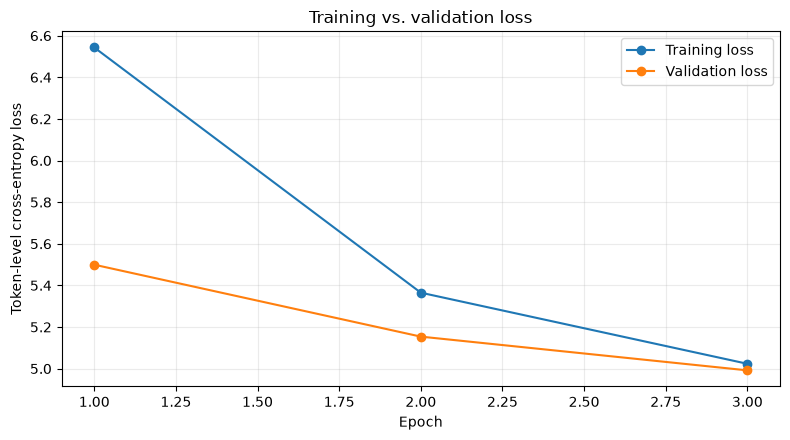

Saved learning curve to: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\learning_curves.png


In [13]:
try:
    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 4.5))
    plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o", label="Training loss")
    plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], marker="o", label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Token-level cross-entropy loss")
    plt.title("Training vs. validation loss")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=160)
    plt.show()
    print("Saved learning curve to:", OUTPUT_DIR / "learning_curves.png")
except ImportError:
    print("Matplotlib is missing; install it with `python -m pip install matplotlib` to plot learning curves.")

## 11. Reload the best checkpoint and evaluate on the held-out test split

The test split is kept separate from training and validation. Its loss/perplexity is a useful language-modeling indicator, but neither metric alone measures human conversational quality. We will also inspect generated replies and should preserve examples of failures in the project README.

In [14]:
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_CHECKPOINT_PATH}. Run the training cell first.")

best_checkpoint = safe_torch_load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(DEVICE).eval()
print("Loaded best checkpoint from epoch:", best_checkpoint["epoch"])
print("Best validation loss:", round(best_checkpoint["validation_loss"], 4))

test_loss = run_epoch(test_loader, training=False)
test_perplexity = math.exp(min(test_loss, 20.0))
print(f"Held-out test loss: {test_loss:.4f}")
print(f"Held-out test perplexity (capped display): {test_perplexity:.2f}")
print("Do not present these as response-quality scores; include them as language-modeling metrics.")

Loaded best checkpoint from epoch: 3
Best validation loss: 4.9918


Held-out test loss: 4.9324
Held-out test perplexity (capped display): 138.71
Do not present these as response-quality scores; include them as language-modeling metrics.


## 12. Response generation

The decoder supports greedy decoding and top-k/top-p sampling. Sampling can add variety but may also make replies less coherent. The repetition penalty is a heuristic, not a guaranteed quality improvement. Compare outputs on fixed prompts before deciding which settings work best.

In [15]:
@torch.inference_mode()
def generate_response(
    context,
    max_new_tokens=25,
    temperature=0.8,
    top_k=40,
    top_p=0.90,
    do_sample=True,
    repetition_penalty=1.12,
    model_obj=None,
    tokenizer_obj=None,
    device_obj=None,
    model_config=None,
):
    model_obj = model_obj or model
    tokenizer_obj = tokenizer_obj or tokenizer
    device_obj = device_obj or DEVICE
    model_config = model_config or MODEL_CONFIG
    if isinstance(context, str):
        context = [context]
    context_turn_limit = int(TRAINING_CONFIG.get("context_turns", CONTEXT_TURNS))
    context = list(context)[-context_turn_limit:]
    source_ids = tokenizer_obj.encode_context(context, max_len=model_config["max_seq_len"])
    source = torch.tensor([source_ids], dtype=torch.long, device=device_obj)
    generated = [BOS_ID]
    max_steps = max(1, min(int(max_new_tokens), model_config["max_seq_len"] - 1))
    model_obj.eval()

    for _ in range(max_steps):
        target_input = torch.tensor([generated], dtype=torch.long, device=device_obj)
        logits = model_obj(source, target_input)[0, -1].float()
        # These tokens must never be emitted as normal dialogue text.
        for forbidden_id in (PAD_ID, BOS_ID, TURN_ID, UNK_ID):
            logits[forbidden_id] = -float("inf")

        # Avoid a response made only of punctuation/end tokens: require at least one lexical word.
        punctuation = {".", "!", "?", ",", ";", ":"}
        emitted_words = [tokenizer_obj.idx2word.get(token_id, "") for token_id in generated[1:]]
        has_lexical_word = any(word and word not in punctuation for word in emitted_words)
        lexical_ids_exist = any(
            idx >= len(SPECIAL_TOKENS) and word not in punctuation
            for word, idx in tokenizer_obj.word2idx.items()
        )
        if not has_lexical_word and lexical_ids_exist:
            logits[EOS_ID] = -float("inf")
            for punctuation_token in punctuation:
                punctuation_id = tokenizer_obj.word2idx.get(punctuation_token)
                if punctuation_id is not None:
                    logits[punctuation_id] = -float("inf")

        if repetition_penalty and repetition_penalty > 1.0:
            for token_id in set(generated[1:]):
                if token_id < logits.numel():
                    logits[token_id] = logits[token_id] * repetition_penalty if logits[token_id] < 0 else logits[token_id] / repetition_penalty

        if not do_sample or temperature <= 0:
            next_id = int(torch.argmax(logits).item())
        else:
            logits = logits / max(float(temperature), 1e-4)
            if top_k and top_k > 0 and top_k < logits.numel():
                cutoff = torch.topk(logits, int(top_k)).values[-1]
                logits[logits < cutoff] = -float("inf")
            if top_p and 0 < top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.softmax(sorted_logits, dim=-1).cumsum(dim=-1)
                remove_sorted = cumulative_probs > top_p
                remove_sorted[1:] = remove_sorted[:-1].clone()
                remove_sorted[0] = False
                logits[sorted_indices[remove_sorted]] = -float("inf")
            probabilities = torch.softmax(logits, dim=-1)
            if not torch.isfinite(probabilities).all() or probabilities.sum() <= 0:
                next_id = int(torch.argmax(logits).item())
            else:
                next_id = int(torch.multinomial(probabilities, num_samples=1).item())

        if next_id == EOS_ID:
            break
        generated.append(next_id)
        if len(generated) >= model_config["max_seq_len"]:
            break

    return tokenizer_obj.decode(generated[1:])

print("Generation function ready.")

Generation function ready.


In [16]:
# Fixed sample prompts to inspect the model after training.
# Keep these prompts fixed when comparing settings or future model versions.
SAMPLE_PROMPTS = [
    ["Hello!"],
    ["How are you?"],
    ["What do you want to do today?"],
    ["I am sorry."],
    ["I do not understand."],
]

for prompt in SAMPLE_PROMPTS:
    reply = generate_response(prompt, do_sample=False, max_new_tokens=20)
    print("Context:", " / ".join(prompt))
    print("Reply:  ", reply or "[empty response]")
    print("-" * 60)

Context: Hello!
Reply:   I don't know.
------------------------------------------------------------
Context: How are you?
Reply:   I don't know.
------------------------------------------------------------
Context: What do you want to do today?
Reply:   I don't know.
------------------------------------------------------------
Context: I am sorry.
Reply:   I don't know.
------------------------------------------------------------


Context: I do not understand.
Reply:   I don't know.
------------------------------------------------------------


## 13. Optional interactive console chat

This cell is disabled by default so that running all notebook cells never gets stuck waiting for input. Change `RUN_CONSOLE_CHAT` to `True` and re-run the cell to chat in the notebook.

In [17]:
RUN_CONSOLE_CHAT = False  # change to True to launch an interactive loop

if RUN_CONSOLE_CHAT:
    chat_history = []
    print("Type 'quit' to stop. This is a demo of the trained model, not a general-purpose assistant.")
    while True:
        user_text = input("You: ").strip()
        if user_text.lower() in {"quit", "exit", "q"}:
            break
        if not user_text:
            continue
        chat_history.append(user_text)
        chat_history = chat_history[-CONTEXT_TURNS:]
        bot_text = generate_response(chat_history, do_sample=True)
        print("Bot:", bot_text or "[empty response]")
        chat_history.append(bot_text)
        chat_history = chat_history[-CONTEXT_TURNS:]
else:
    print("Console chat is disabled. Set RUN_CONSOLE_CHAT = True to enable it.")

Console chat is disabled. Set RUN_CONSOLE_CHAT = True to enable it.


## 14. Export the portfolio demo

The next cell writes three files into the current project directory:

- `chatbot_runtime.py` — model definition, checkpoint loader, and generation function.
- `streamlit_app.py` — chat UI with generation settings and latency display.
- `requirements.txt` — minimal packages for running the app.

The Streamlit app expects the checkpoint at `artifacts/chatbot_transformer_best.pt`, which this notebook saves during training. Run the export cell after the training/checkpoint cells.

In [18]:
# Export a standalone runtime and Streamlit application. This cell is safe to re-run.
RUNTIME_SOURCE = 'import math\nimport re\nimport unicodedata\nfrom pathlib import Path\nimport torch\nimport torch.nn as nn\n\nPAD_TOKEN, BOS_TOKEN, EOS_TOKEN, UNK_TOKEN, TURN_TOKEN = "<pad>", "<bos>", "<eos>", "<unk>", "<turn>"\nSPECIAL_TOKENS = [PAD_TOKEN, BOS_TOKEN, EOS_TOKEN, UNK_TOKEN, TURN_TOKEN]\nPAD_ID, BOS_ID, EOS_ID, UNK_ID, TURN_ID = range(len(SPECIAL_TOKENS))\nTOKEN_PATTERN = re.compile(r"[a-z]+(?:\'[a-z]+)?|[0-9]+|[.!?,;:]")\n\ndef normalize_text(text):\n    text = unicodedata.normalize("NFD", str(text))\n    text = "".join(ch for ch in text if unicodedata.category(ch) != "Mn")\n    return re.sub(r"\\s+", " ", text.lower().strip())\n\ndef tokenize_text(text):\n    return TOKEN_PATTERN.findall(normalize_text(text))\n\nclass WordTokenizer:\n    def __init__(self, word2idx):\n        self.word2idx = {str(k): int(v) for k, v in word2idx.items()}\n        self.idx2word = {idx: word for word, idx in self.word2idx.items()}\n        for idx, token in enumerate(SPECIAL_TOKENS):\n            if self.word2idx.get(token) != idx:\n                raise ValueError(f"Incompatible tokenizer: {token} must have ID {idx}")\n    def encode_text(self, text):\n        return [self.word2idx.get(token, UNK_ID) for token in tokenize_text(text)]\n    def encode_context(self, context, max_len=40):\n        if isinstance(context, str):\n            context = [context]\n        ids = []\n        for i, turn in enumerate(context):\n            if i:\n                ids.append(TURN_ID)\n            ids.extend(self.encode_text(turn))\n        return ids[-max_len:] or [UNK_ID]\n    def decode(self, token_ids):\n        skip = {PAD_ID, BOS_ID, EOS_ID, TURN_ID, UNK_ID}\n        words = [self.idx2word.get(int(idx), "") for idx in token_ids if int(idx) not in skip]\n        text = " ".join(word for word in words if word)\n        text = re.sub(r"\\s+([.!?,;:])", r"\\1", text)\n        text = re.sub(r"\\s+", " ", text).strip()\n        return text[:1].upper() + text[1:] if text else ""\n\nclass DialogueTransformer(nn.Module):\n    def __init__(self, vocab_size, d_model=128, nhead=4, num_encoder_layers=2, num_decoder_layers=2,\n                 dim_feedforward=256, dropout=0.1, max_seq_len=40):\n        super().__init__()\n        if d_model % nhead != 0:\n            raise ValueError("d_model must be divisible by nhead")\n        self.vocab_size, self.d_model, self.max_seq_len = vocab_size, d_model, max_seq_len\n        self.src_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)\n        self.tgt_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)\n        self.src_position = nn.Embedding(max_seq_len, d_model)\n        self.tgt_position = nn.Embedding(max_seq_len, d_model)\n        self.embedding_dropout = nn.Dropout(dropout)\n        self.transformer = nn.Transformer(d_model=d_model, nhead=nhead,\n            num_encoder_layers=num_encoder_layers, num_decoder_layers=num_decoder_layers,\n            dim_feedforward=dim_feedforward, dropout=dropout, batch_first=True)\n        self.output_projection = nn.Linear(d_model, vocab_size)\n        self._reset_parameters()\n    def _reset_parameters(self):\n        for p in self.parameters():\n            if p.dim() > 1:\n                nn.init.xavier_uniform_(p)\n        with torch.no_grad():\n            self.src_embedding.weight[PAD_ID].zero_()\n            self.tgt_embedding.weight[PAD_ID].zero_()\n    def _embed(self, ids, token_embedding, position_embedding):\n        batch, length = ids.shape\n        if length > self.max_seq_len:\n            raise ValueError(f"Sequence length {length} exceeds {self.max_seq_len}")\n        positions = torch.arange(length, device=ids.device).unsqueeze(0).expand(batch, -1)\n        return self.embedding_dropout(token_embedding(ids) * math.sqrt(self.d_model) + position_embedding(positions))\n    def forward(self, source_ids, target_input_ids):\n        src_pad = source_ids.eq(PAD_ID)\n        tgt_pad = target_input_ids.eq(PAD_ID)\n        length = target_input_ids.size(1)\n        causal = torch.triu(torch.ones(length, length, dtype=torch.bool, device=target_input_ids.device), diagonal=1)\n        out = self.transformer(\n            src=self._embed(source_ids, self.src_embedding, self.src_position),\n            tgt=self._embed(target_input_ids, self.tgt_embedding, self.tgt_position),\n            tgt_mask=causal,\n            src_key_padding_mask=src_pad,\n            tgt_key_padding_mask=tgt_pad,\n            memory_key_padding_mask=src_pad,\n        )\n        return self.output_projection(out)\n\ndef choose_device():\n    if torch.cuda.is_available():\n        return torch.device("cuda")\n    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():\n        return torch.device("mps")\n    return torch.device("cpu")\n\ndef safe_load_checkpoint(path, device):\n    try:\n        return torch.load(path, map_location=device, weights_only=False)\n    except TypeError:\n        return torch.load(path, map_location=device)\n\ndef load_chatbot(checkpoint_path):\n    device = choose_device()\n    checkpoint_path = Path(checkpoint_path)\n    if not checkpoint_path.is_file():\n        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}. Run training in the notebook first.")\n    checkpoint = safe_load_checkpoint(checkpoint_path, device)\n    config = checkpoint["model_config"]\n    tokenizer = WordTokenizer(checkpoint["tokenizer_state"]["word2idx"])\n    model = DialogueTransformer(vocab_size=len(tokenizer.word2idx), **config)\n    model.load_state_dict(checkpoint["model_state_dict"])\n    model.to(device).eval()\n    return model, tokenizer, device, checkpoint\n\n@torch.inference_mode()\ndef generate_response(model, tokenizer, context, device, model_config, context_turns=3,\n                     max_new_tokens=25, temperature=0.8, top_k=40, top_p=0.90,\n                     do_sample=True, repetition_penalty=1.12):\n    if isinstance(context, str):\n        context = [context]\n    context = list(context)[-max(1, int(context_turns)):]\n    source_ids = tokenizer.encode_context(context, max_len=model_config["max_seq_len"])\n    source = torch.tensor([source_ids], dtype=torch.long, device=device)\n    generated = [BOS_ID]\n    max_steps = max(1, min(int(max_new_tokens), model_config["max_seq_len"] - 1))\n    model.eval()\n    for _ in range(max_steps):\n        target = torch.tensor([generated], dtype=torch.long, device=device)\n        logits = model(source, target)[0, -1].float()\n        for forbidden in (PAD_ID, BOS_ID, TURN_ID, UNK_ID):\n            logits[forbidden] = -float("inf")\n        punctuation = {".", "!", "?", ",", ";", ":"}\n        emitted_words = [tokenizer.idx2word.get(token_id, "") for token_id in generated[1:]]\n        has_lexical_word = any(word and word not in punctuation for word in emitted_words)\n        lexical_ids_exist = any(idx >= len(SPECIAL_TOKENS) and word not in punctuation for word, idx in tokenizer.word2idx.items())\n        if not has_lexical_word and lexical_ids_exist:\n            logits[EOS_ID] = -float("inf")\n            for punctuation_token in punctuation:\n                punctuation_id = tokenizer.word2idx.get(punctuation_token)\n                if punctuation_id is not None:\n                    logits[punctuation_id] = -float("inf")\n        if repetition_penalty and repetition_penalty > 1:\n            for token_id in set(generated[1:]):\n                if token_id < logits.numel():\n                    logits[token_id] = logits[token_id] * repetition_penalty if logits[token_id] < 0 else logits[token_id] / repetition_penalty\n        if not do_sample or temperature <= 0:\n            next_id = int(torch.argmax(logits).item())\n        else:\n            logits = logits / max(float(temperature), 1e-4)\n            if top_k and 0 < top_k < logits.numel():\n                cutoff = torch.topk(logits, int(top_k)).values[-1]\n                logits[logits < cutoff] = -float("inf")\n            if top_p and 0 < top_p < 1:\n                sorted_logits, sorted_indices = torch.sort(logits, descending=True)\n                cumulative = torch.softmax(sorted_logits, dim=-1).cumsum(-1)\n                remove = cumulative > top_p\n                remove[1:] = remove[:-1].clone()\n                remove[0] = False\n                logits[sorted_indices[remove]] = -float("inf")\n            probs = torch.softmax(logits, dim=-1)\n            if not torch.isfinite(probs).all() or probs.sum() <= 0:\n                next_id = int(torch.argmax(logits).item())\n            else:\n                next_id = int(torch.multinomial(probs, 1).item())\n        if next_id == EOS_ID:\n            break\n        generated.append(next_id)\n        if len(generated) >= model_config["max_seq_len"]:\n            break\n    return tokenizer.decode(generated[1:])\n'
STREAMLIT_APP_SOURCE = 'from pathlib import Path\nimport time\nimport streamlit as st\nfrom chatbot_runtime import load_chatbot, generate_response\n\nBASE_DIR = Path(__file__).resolve().parent\nCHECKPOINT_PATH = BASE_DIR / "artifacts" / "chatbot_transformer_best.pt"\n\nst.set_page_config(page_title="Cornell Dialogue AI", page_icon="💬", layout="centered")\nst.title("Intelligent Conversational Chatbot")\nst.caption("Custom PyTorch encoder–decoder Transformer trained on the Cornell Movie Dialogs Corpus.")\nst.info("This is an experimental dialogue model, not a factual assistant. Responses can be repetitive, irrelevant, or inappropriate because the training corpus contains movie dialogue.")\n\n@st.cache_resource\ndef cached_bot(checkpoint_path):\n    return load_chatbot(checkpoint_path)\n\nif not CHECKPOINT_PATH.exists():\n    st.error(f"Checkpoint not found: {CHECKPOINT_PATH}\\n\\nRun the notebook\'s training and export cells first. Keep the artifacts folder beside this file.")\n    st.stop()\n\ntry:\n    model, tokenizer, device, checkpoint = cached_bot(str(CHECKPOINT_PATH))\nexcept Exception as error:\n    st.exception(error)\n    st.stop()\n\ntraining_config = checkpoint.get("training_config", {})\ncontext_turns = int(training_config.get("context_turns", 3))\n\nwith st.sidebar:\n    st.header("Generation settings")\n    st.caption(f"Inference device: {device}")\n    st.caption(f"Checkpoint epoch: {checkpoint.get(\'epoch\', \'unknown\')}")\n    strategy = st.radio("Decoding", ["Top-k / top-p sampling", "Greedy"], index=0)\n    max_new_tokens = st.slider("Maximum response tokens", 5, 39, 25)\n    temperature = st.slider("Temperature", 0.2, 1.5, 0.8, 0.05, disabled=(strategy == "Greedy"))\n    top_k = st.slider("Top-k", 0, 100, 40, disabled=(strategy == "Greedy"))\n    top_p = st.slider("Top-p", 0.10, 1.0, 0.90, 0.05, disabled=(strategy == "Greedy"))\n    repetition_penalty = st.slider("Repetition penalty", 1.0, 1.5, 1.12, 0.02)\n    if st.button("Clear conversation", use_container_width=True):\n        st.session_state.messages = []\n        st.rerun()\n\nif "messages" not in st.session_state:\n    st.session_state.messages = []\n\nif not st.session_state.messages:\n    st.markdown("#### Try a conversation")\n    st.write("Hello! · How are you? · What do you want to do today?")\n\nfor message in st.session_state.messages:\n    with st.chat_message(message["role"]):\n        st.markdown(message["content"])\n        if message.get("latency") is not None:\n            st.caption(f"Generated in {message[\'latency\']:.2f} seconds")\n\nprompt = st.chat_input("Write a message...")\nif prompt:\n    st.session_state.messages.append({"role": "user", "content": prompt})\n    with st.chat_message("user"):\n        st.markdown(prompt)\n    recent = [m["content"] for m in st.session_state.messages if m["role"] in ("user", "assistant")][-context_turns:]\n    start = time.perf_counter()\n    with st.chat_message("assistant"):\n        with st.spinner("Generating response..."):\n            try:\n                answer = generate_response(\n                    model, tokenizer, recent, device, checkpoint["model_config"],\n                    context_turns=context_turns,\n                    max_new_tokens=max_new_tokens,\n                    temperature=temperature,\n                    top_k=top_k,\n                    top_p=top_p,\n                    do_sample=(strategy != "Greedy"),\n                    repetition_penalty=repetition_penalty,\n                )\n            except Exception as error:\n                st.error(f"Generation failed: {error}")\n                answer = "I couldn\'t generate a reply. Check the notebook checkpoint and logs."\n        elapsed = time.perf_counter() - start\n        st.markdown(answer or "[The model returned an empty response. Try a different prompt or decoding setting.]")\n        st.caption(f"Generated in {elapsed:.2f} seconds")\n    st.session_state.messages.append({"role": "assistant", "content": answer or "", "latency": elapsed})\n' 

runtime_path = PROJECT_DIR / "chatbot_runtime.py"
app_path = PROJECT_DIR / "streamlit_app.py"
requirements_path = PROJECT_DIR / "requirements.txt"
runtime_path.write_text(RUNTIME_SOURCE, encoding="utf-8")
app_path.write_text(STREAMLIT_APP_SOURCE, encoding="utf-8")
requirements_path.write_text("torch>=2.0\nstreamlit>=1.32\n", encoding="utf-8")
print("Created:", runtime_path)
print("Created:", app_path)
print("Created:", requirements_path)
print("Checkpoint required by the app:", BEST_CHECKPOINT_PATH)
print("\nTo launch from a terminal in this project directory:")
print("  python -m pip install -r requirements.txt")
print("  streamlit run streamlit_app.py")

Created: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\chatbot_runtime.py
Created: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\streamlit_app.py
Created: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\requirements.txt
Checkpoint required by the app: C:\Users\suraj\Downloads\Intelligent_Chatbot_Development-project-main\artifacts\chatbot_transformer_best.pt

To launch from a terminal in this project directory:
  python -m pip install -r requirements.txt
  streamlit run streamlit_app.py


## 15. Final project checklist

Before presenting this project in your portfolio, verify the following:

- [ ] Run the notebook from a clean kernel on the local Cornell raw files.
- [ ] Keep the best checkpoint and tokenizer in the `artifacts/` folder.
- [ ] Run the Streamlit app and record a short demo.
- [ ] Test at least 20 fixed prompts and save representative good and bad outputs.
- [ ] Report the actual model configuration, examples used, training time, device, test loss, and inference latency.
- [ ] State clearly that the vocabulary is word-level and the first laptop run is intentionally limited in size.
- [ ] Do not claim improved accuracy or human-level conversational quality without measured evidence.

### Useful next adjustments

If the first run completes comfortably, change `MAX_TRAIN_EXAMPLES` from `4000` to `10000` or more and raise `EPOCHS` to `5–10`, checking validation loss after each run. If CPU training is too slow, reduce `D_MODEL` to `96`, layer counts to `1`, or the number of training examples. If using an NVIDIA GPU, install a PyTorch build compatible with the GPU and CUDA version; then restart the notebook kernel and confirm the device cell reports `cuda`.